# Web Server Log Analytics & Monitoring System

## 1. Setup and project paths


In [7]:
import csv
import json
import os
import shlex
from pathlib import Path
from collections import Counter
from urllib.parse import urlsplit

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

PROJECT_DIR = Path(os.environ.get("ALB_PROJECT_DIR", r"C:\projects\Python Project"))
LOG_FILE = PROJECT_DIR / "mylog.log"
if not LOG_FILE.is_file() and (PROJECT_DIR / "data" / "raw" / "mylog.log").is_file():
    LOG_FILE = PROJECT_DIR / "data" / "raw" / "mylog.log"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORT_DIR = PROJECT_DIR / "reports" / "csv"
CHART_DIR = PROJECT_DIR / "reports" / "charts"

for folder in (PROCESSED_DIR, REPORT_DIR, CHART_DIR):
    folder.mkdir(parents=True, exist_ok=True)

if not LOG_FILE.is_file():
    raise FileNotFoundError(
        f"Log file not found: {LOG_FILE}\nCopy mylog.log into the project folder and rerun this cell."
    )

print(f"Project folder: {PROJECT_DIR}")
print(f"Input log: {LOG_FILE}")
print(f"Log size: {LOG_FILE.stat().st_size:,} bytes")

Project folder: C:\projects\Python Project
Input log: C:\projects\Python Project\mylog.log
Log size: 227,567 bytes


## 2.original script(Stage 1)


In [8]:
def frequency(values):
    '''Count values with a new dictionary, so separate counts stay separate.'''
    counts = {}
    for value in values:
        if value not in counts:
            counts[value] = 1
        else:
            counts[value] += 1
    return counts


def write_frequency_csv(counts, value_name, output_path):
    '''Write one frequency table to its own CSV file.'''
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with output_path.open("w", newline="", encoding="utf-8") as output_file:
        writer = csv.writer(output_file)
        writer.writerow([value_name, "request_count"])
        for value, count in sorted(counts.items(), key=lambda pair: (-pair[1], pair[0])):
            writer.writerow([value, count])

## 3. Understand and parse the ALB record format (Stage 2)

The supplied entries have 29 standard ALB fields. Positions used by the original script are zero-based field 3 for client address and field 8 for the load balancer status. The quoted request line and user-agent can contain spaces, so `shlex.split()` is used to respect quotes. A dash (`-`) represents an unavailable value. The parser also keeps fields appended after the standard 29.

Each valid row becomes a dictionary with named fields. We derive `client_ip`, numeric ports, HTTP method, and request path for analysis. We keep load balancer status and target status in separate columns.

In [9]:
ALB_FIELDS = [
    "type", "time", "elb", "client_port", "target_port",
    "request_processing_time", "target_processing_time", "response_processing_time",
    "elb_status_code", "target_status_code", "received_bytes", "sent_bytes",
    "request", "user_agent", "ssl_cipher", "ssl_protocol", "target_group_arn",
    "trace_id", "domain_name", "chosen_cert_arn", "matched_rule_priority",
    "request_creation_time", "actions_executed", "redirect_url", "error_reason",
    "target_port_list", "target_status_code_list", "classification",
    "classification_reason",
]
FLOAT_FIELDS = {
    "request_processing_time", "target_processing_time", "response_processing_time"
}
INT_FIELDS = {
    "elb_status_code", "target_status_code", "received_bytes", "sent_bytes",
    "matched_rule_priority",
}


class LogParseError(ValueError):
    '''A line is malformed or does not have the required ALB fields.'''


def split_address(value):
    if value in ("", "-"):
        return None, None
    host, separator, port = value.rpartition(":")
    if not separator or not host or not port.isdigit():
        raise LogParseError(f"Invalid address and port: {value!r}")
    return host.strip("[]"), int(port)


def parse_alb_line(line):
    try:
        fields = shlex.split(line, posix=True)
    except ValueError as error:
        raise LogParseError(f"Malformed quotes: {error}") from error

    if len(fields) < len(ALB_FIELDS):
        raise LogParseError(f"Expected 29 or more fields; found {len(fields)}")

    row = dict(zip(ALB_FIELDS, fields[:len(ALB_FIELDS)]))
    for index, value in enumerate(fields[len(ALB_FIELDS):], start=30):
        row[f"extra_field_{index}"] = value

    for name in FLOAT_FIELDS:
        try:
            row[name] = None if row[name] == "-" else float(row[name])
        except ValueError as error:
            raise LogParseError(f"Invalid number for {name}: {row[name]!r}") from error
    for name in INT_FIELDS:
        try:
            row[name] = None if row[name] == "-" else int(row[name])
        except ValueError as error:
            raise LogParseError(f"Invalid integer for {name}: {row[name]!r}") from error

    # Convert ALB's dash placeholder to Python's missing value for text columns.
    for name in ALB_FIELDS:
        if name not in FLOAT_FIELDS and name not in INT_FIELDS:
            if row[name] == "-":
                row[name] = None

    row["client_ip"], row["client_port_number"] = split_address(fields[3])
    row["target_ip"], row["target_port_number"] = split_address(fields[4])

    request = fields[12]
    request_parts = request.split(" ", 2) if request != "-" else []
    if len(request_parts) == 3:
        method, request_url, protocol = request_parts
        row["request_method"] = method
        row["request_path"] = urlsplit(request_url).path or "/"
        row["request_protocol"] = protocol
    else:
        row["request_method"] = None
        row["request_path"] = None
        row["request_protocol"] = None
    return row


print(f"Standard ALB field count: {len(ALB_FIELDS)}")

Standard ALB field count: 29


## 4. Parse the file and keep invalid records (Stages 2–3)

We process one line at a time. Valid records go into a list for this small 344-line dataset; invalid lines are recorded with their line number and reason. The two frequency tables use separate calls to `frequency()` and separate output filenames.

In [10]:
records = []
invalid_records = []

with LOG_FILE.open("r", encoding="utf-8") as log_file:
    for line_number, raw_line in enumerate(log_file, start=1):
        if not raw_line.strip():
            continue
        try:
            records.append(parse_alb_line(raw_line))
        except LogParseError as error:
            invalid_records.append({
                "line_number": line_number,
                "reason": str(error),
                "raw_line": raw_line.rstrip("\r\n"),
            })

if not records:
    raise ValueError("No valid ALB records were parsed; check the input format.")

processed_csv = PROCESSED_DIR / "cleaned_logs.csv"
fieldnames = list(records[0].keys())
for record in records[1:]:
    for name in record:
        if name not in fieldnames:
            fieldnames.append(name)
with processed_csv.open("w", newline="", encoding="utf-8") as output_file:
    writer = csv.DictWriter(output_file, fieldnames=fieldnames, extrasaction="ignore")
    writer.writeheader()
    writer.writerows(records)

invalid_csv = REPORT_DIR / "invalid_records.csv"
with invalid_csv.open("w", newline="", encoding="utf-8") as output_file:
    writer = csv.DictWriter(output_file, fieldnames=["line_number", "reason", "raw_line"])
    writer.writeheader()
    writer.writerows(invalid_records)

client_ip_counts = frequency(
    row["client_ip"] for row in records if row["client_ip"] is not None
)
lb_status_counts = frequency(
    str(row["elb_status_code"]) for row in records if row["elb_status_code"] is not None
)
write_frequency_csv(client_ip_counts, "client_ip", REPORT_DIR / "client_ip_frequency.csv")
write_frequency_csv(lb_status_counts, "load_balancer_status_code", REPORT_DIR / "load_balancer_status_frequency.csv")

print(f"Parsed records: {len(records)}")
print(f"Invalid records: {len(invalid_records)}")
print(f"Unique client IPs: {len(client_ip_counts)}")
print(f"Processed CSV: {processed_csv}")

Parsed records: 344
Invalid records: 0
Unique client IPs: 7
Processed CSV: C:\projects\Python Project\data\processed\cleaned_logs.csv


## 5. Load, inspect, and clean with Pandas (Stage 4)

`DataFrame` is a table with named columns. `head()` previews rows, `info()` shows column types and missing-value counts, and `describe()` summarizes numerical columns. Timestamps and numbers are converted to useful types. Repeated identical log rows are retained because they can be separate requests and the file has no request ID for safely removing duplicates.

In [11]:
df = pd.read_csv(processed_csv)
for column in ("time", "request_creation_time"):
    if column in df.columns:
        df[column] = pd.to_datetime(df[column], utc=True, errors="coerce")
for column in FLOAT_FIELDS | {"elb_status_code", "target_status_code", "received_bytes", "sent_bytes"}:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

print("Preview of analysis-friendly columns:")
display(df[["time", "client_ip", "request_method", "request_path",
            "elb_status_code", "target_status_code"]].head())
print("\nDataFrame information:")
df.info()
print("\nNumeric summary:")
display(df[["request_processing_time", "target_processing_time",
            "response_processing_time", "received_bytes", "sent_bytes"]].describe())

Preview of analysis-friendly columns:


,time,client_ip,request_method,request_path,elb_status_code,target_status_code
0,2021-10-05 23:55:13.192364+00:00,10.73.146.189,GET,/workspaces/00000000-0000-0000-0000-0000000000...,304,304
1,2021-10-05 23:55:13.192432+00:00,10.73.146.189,GET,/workspaces/00000000-0000-0000-0000-0000000000...,304,304
2,2021-10-05 23:55:13.233877+00:00,10.73.146.189,GET,/workspaces/00000000-0000-0000-0000-0000000000...,304,304
3,2021-10-05 23:55:37.616209+00:00,10.73.145.224,GET,/workspaces/59e7a9c6-696e-4d63-9ab9-3b7cf164ce...,304,304
4,2021-10-05 23:55:37.628812+00:00,10.73.145.224,GET,/workspaces/59e7a9c6-696e-4d63-9ab9-3b7cf164ce...,304,304



DataFrame information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 36 columns):
 #   Column                    Non-Null Count  Dtype              
---  ------                    --------------  -----              
 0   type                      344 non-null    object             
 1   time                      344 non-null    datetime64[ns, UTC]
 2   elb                       344 non-null    object             
 3   client_port               344 non-null    object             
 4   target_port               344 non-null    object             
 5   request_processing_time   344 non-null    float64            
 6   target_processing_time    344 non-null    float64            
 7   response_processing_time  344 non-null    float64            
 8   elb_status_code           344 non-null    int64              
 9   target_status_code        344 non-null    int64              
 10  received_bytes            344 non-null    int64              


,request_processing_time,target_processing_time,response_processing_time,received_bytes,sent_bytes
count,344.000000,344.000000,344.0,344.000000,344.000000
mean,0.000012,0.002581,0.0,2049.497093,722.938953
std,0.000132,0.009892,0.0,8469.683594,2167.356714
min,0.000000,0.000000,0.0,307.000000,195.000000
25%,0.000000,0.000000,0.0,353.500000,214.000000
50%,0.000000,0.001000,0.0,401.000000,264.000000
75%,0.000000,0.002000,0.0,448.500000,340.000000
max,0.002000,0.092000,0.0,75265.000000,18344.000000


## 6. Traffic analysis with Pandas (Stage 3–4)

`value_counts()` finds the most common values. `groupby()` and `resample()` summarize records over time. We export client, request path, minute, and hour tables to CSV for review.

In [12]:
requests_by_ip = (
    df["client_ip"].dropna().value_counts().rename_axis("client_ip")
      .reset_index(name="requests")
)
requests_by_path = (
    df["request_path"].dropna().value_counts().rename_axis("request_path")
      .reset_index(name="requests")
)
requests_by_minute = (
    df.dropna(subset=["time"]).set_index("time").resample("1min").size()
      .rename_axis("minute_utc").reset_index(name="requests")
)
requests_by_hour = (
    df.dropna(subset=["time"]).assign(hour_utc=lambda data: data["time"].dt.hour)
      .groupby("hour_utc").size().rename("requests").reset_index()
)

requests_by_ip.to_csv(REPORT_DIR / "requests_by_client_ip.csv", index=False)
requests_by_path.head(50).to_csv(REPORT_DIR / "top_request_paths.csv", index=False)
requests_by_minute.to_csv(REPORT_DIR / "requests_over_time.csv", index=False)
requests_by_hour.to_csv(REPORT_DIR / "requests_by_hour.csv", index=False)

traffic_summary = {
    "total_requests": int(len(df)),
    "unique_client_ips": int(df["client_ip"].nunique()),
    "time_start_utc": df["time"].min().isoformat(),
    "time_end_utc": df["time"].max().isoformat(),
}
print(traffic_summary)
display(requests_by_ip.head(10))

{'total_requests': 344, 'unique_client_ips': 7, 'time_start_utc': '2021-10-05T23:55:13.192364+00:00', 'time_end_utc': '2021-10-05T23:59:57.604600+00:00'}


,client_ip,requests
0,10.73.145.224,107
1,10.73.133.204,96
2,10.73.132.212,47
3,10.73.133.231,44
4,10.73.132.5,38
5,10.73.146.189,6
6,10.73.144.159,6


## 7. HTTP status code analysis (Stage 3–4)

The load balancer response describes what the ALB returned; the target response describes what the backend target returned. We keep them in separate reports. A 304 is `Not Modified`, not a redirect, even though both fall in the 3xx status class. Success percentage here means 2xx responses; error percentage means 4xx and 5xx responses.

In [13]:
REDIRECTION_CODES = {300, 301, 302, 303, 307, 308}

def status_table(column):
    table = df[column].dropna().astype(int).value_counts().sort_index()
    result = table.rename_axis("status_code").reset_index(name="requests")
    def label(code):
        if code in REDIRECTION_CODES:
            return "redirection"
        if code == 304:
            return "not_modified"
        if 200 <= code <= 299:
            return "success"
        if 400 <= code <= 499:
            return "client_error"
        if 500 <= code <= 599:
            return "server_error"
        return "other"
    result["category"] = result["status_code"].map(label)
    return result

lb_status = status_table("elb_status_code")
target_status = status_table("target_status_code")
lb_status.to_csv(REPORT_DIR / "load_balancer_status_codes.csv", index=False)
target_status.to_csv(REPORT_DIR / "target_status_codes.csv", index=False)

status_values = df["elb_status_code"].dropna().astype(int)
status_summary = {
    "load_balancer_counts": {str(k): int(v) for k, v in status_values.value_counts().items()},
    "target_counts": {
        str(k): int(v) for k, v in df["target_status_code"].dropna().astype(int).value_counts().items()
    },
    "successful_2xx": int(status_values.between(200, 299).sum()),
    "redirect_responses": int(status_values.isin(REDIRECTION_CODES).sum()),
    "not_modified_304": int((status_values == 304).sum()),
    "client_errors_4xx": int(status_values.between(400, 499).sum()),
    "server_errors_5xx": int(status_values.between(500, 599).sum()),
    "success_percent": round(status_values.between(200, 299).mean() * 100, 2),
    "error_percent": round(status_values.between(400, 599).mean() * 100, 2),
}
display(lb_status)
print(status_summary)

,status_code,requests,category
0,200,115,success
1,304,186,not_modified
2,404,43,client_error


{'load_balancer_counts': {'304': 186, '200': 115, '404': 43}, 'target_counts': {'304': 186, '200': 115, '404': 43}, 'successful_2xx': 115, 'redirect_responses': 0, 'not_modified_304': 186, 'client_errors_4xx': 43, 'server_errors_5xx': 0, 'success_percent': np.float64(33.43), 'error_percent': np.float64(12.5)}


## 8. NumPy and performance analysis (Stage 5)

NumPy arrays make numerical operations concise and fast. We calculate mean, median, population standard deviation, minimum, maximum, and 95th percentile for each available timing field. ALB timing fields are measured in seconds; a missing dash is kept missing rather than changed to zero. Byte counts are also summarized.

In [14]:
def numpy_stats(series):
    values = pd.to_numeric(series, errors="coerce").dropna().to_numpy(dtype=float)
    if values.size == 0:
        return {"count": 0, "mean": None, "median": None, "std_dev": None,
                "minimum": None, "maximum": None, "p95": None}
    # NumPy indexing and slicing examples: first value and first five values.
    first_value = values[0]
    first_five = values[:5]
    return {
        "count": int(values.size),
        "first_value_example": float(first_value),
        "first_five_example": first_five.tolist(),
        "mean": float(np.mean(values)),
        "median": float(np.median(values)),
        "std_dev": float(np.std(values)),
        "minimum": float(np.min(values)),
        "maximum": float(np.max(values)),
        "p95": float(np.percentile(values, 95)),
    }

timing_columns = [
    "request_processing_time", "target_processing_time", "response_processing_time"
]
performance_summary = {column: numpy_stats(df[column]) for column in timing_columns}
performance_summary["bytes_sent"] = numpy_stats(df["sent_bytes"])
performance_summary["bytes_received"] = numpy_stats(df["received_bytes"])

slowest_requests = df.nlargest(10, "target_processing_time")[[
    "time", "client_ip", "request_path", "elb_status_code", "target_status_code",
    "target_processing_time",
]]
slowest_requests.to_csv(REPORT_DIR / "slowest_requests.csv", index=False)
print(json.dumps(performance_summary, indent=2))
display(slowest_requests.head())

{
  "request_processing_time": {
    "count": 344,
    "first_value_example": 0.0,
    "first_five_example": [
      0.0,
      0.0,
      0.0,
      0.0,
      0.0
    ],
    "mean": 1.1627906976744187e-05,
    "median": 0.0,
    "std_dev": 0.0001315547499881949,
    "minimum": 0.0,
    "maximum": 0.002,
    "p95": 0.0
  },
  "target_processing_time": {
    "count": 344,
    "first_value_example": 0.001,
    "first_five_example": [
      0.001,
      0.002,
      0.001,
      0.0,
      0.001
    ],
    "mean": 0.0025813953488372098,
    "median": 0.001,
    "std_dev": 0.009877699944447416,
    "minimum": 0.0,
    "maximum": 0.092,
    "p95": 0.006
  },
  "response_processing_time": {
    "count": 344,
    "first_value_example": 0.0,
    "first_five_example": [
      0.0,
      0.0,
      0.0,
      0.0,
      0.0
    ],
    "mean": 0.0,
    "median": 0.0,
    "std_dev": 0.0,
    "minimum": 0.0,
    "maximum": 0.0,
    "p95": 0.0
  },
  "bytes_sent": {
    "count": 344,
    "first_val

,time,client_ip,request_path,elb_status_code,target_status_code,target_processing_time
76,2021-10-05 23:56:56.796006+00:00,10.73.145.224,/workspaces/00000000-0000-0000-0000-0000000000...,200,200,0.092
86,2021-10-05 23:57:21.937888+00:00,10.73.144.159,/workspaces/00000000-0000-0000-0000-0000000000...,200,200,0.086
9,2021-10-05 23:55:39.989060+00:00,10.73.146.189,/workspaces/00000000-0000-0000-0000-0000000000...,200,200,0.085
273,2021-10-05 23:59:37.109960+00:00,10.73.145.224,/workspaces/00000000-0000-0000-0000-0000000000...,200,200,0.085
255,2021-10-05 23:59:05.876118+00:00,10.73.145.224,/workspaces/59e7a9c6-696e-4d63-9ab9-3b7cf164ce...,200,200,0.058


## 9. Potential anomaly exploration (Stage 7)

These simple rules surface records for human review:

- A minute with request volume above the observed 95th percentile.
- A target processing time above the observed 95th percentile.
- A load balancer 5xx response.

The percentile is calculated from this dataset, so it is a descriptive threshold rather than a universal service-level objective. These flags are potential anomalies, not proof of an attack or incident.

In [15]:
potential_flags = []

if not requests_by_minute.empty:
    request_threshold = float(np.percentile(requests_by_minute["requests"].to_numpy(), 95))
    for _, minute_row in requests_by_minute[requests_by_minute["requests"] > request_threshold].iterrows():
        potential_flags.append({
            "kind": "high_request_volume_minute", "time": minute_row["minute_utc"],
            "value": int(minute_row["requests"]), "threshold": request_threshold,
            "rule": "minute count above observed 95th percentile",
        })

target_times = pd.to_numeric(df["target_processing_time"], errors="coerce")
if target_times.notna().any():
    slow_threshold = float(np.percentile(target_times.dropna().to_numpy(), 95))
    for row_index in df.index[target_times > slow_threshold]:
        potential_flags.append({
            "kind": "slow_target_processing", "time": df.at[row_index, "time"],
            "value": float(target_times.at[row_index]), "threshold": slow_threshold,
            "rule": "target time above observed 95th percentile",
        })

for row_index in df.index[pd.to_numeric(df["elb_status_code"], errors="coerce") >= 500]:
    potential_flags.append({
        "kind": "load_balancer_server_error", "time": df.at[row_index, "time"],
        "value": int(df.at[row_index, "elb_status_code"]), "threshold": 500,
        "rule": "load balancer status code in 5xx range",
    })

anomaly_columns = ["kind", "time", "value", "threshold", "rule"]
anomalies = pd.DataFrame(potential_flags, columns=anomaly_columns)
anomalies.to_csv(REPORT_DIR / "potential_anomalies.csv", index=False)
print(f"Potential flags for review: {len(anomalies)}")
display(anomalies.head(10))

Potential flags for review: 17


,kind,time,value,threshold,rule
0,high_request_volume_minute,2021-10-05 23:59:00+00:00,100.000,97.600,minute count above observed 95th percentile
1,slow_target_processing,2021-10-05 23:55:39.989060+00:00,0.085,0.006,target time above observed 95th percentile
2,slow_target_processing,2021-10-05 23:55:55.979750+00:00,0.014,0.006,target time above observed 95th percentile
3,slow_target_processing,2021-10-05 23:55:43.775235+00:00,0.009,0.006,target time above observed 95th percentile
4,slow_target_processing,2021-10-05 23:56:34.561340+00:00,0.010,0.006,target time above observed 95th percentile
5,slow_target_processing,2021-10-05 23:56:44.370576+00:00,0.010,0.006,target time above observed 95th percentile
6,slow_target_processing,2021-10-05 23:56:56.796006+00:00,0.092,0.006,target time above observed 95th percentile
7,slow_target_processing,2021-10-05 23:57:21.937888+00:00,0.086,0.006,target time above observed 95th percentile
8,slow_target_processing,2021-10-05 23:58:14.994457+00:00,0.008,0.006,target time above observed 95th percentile
9,slow_target_processing,2021-10-05 23:58:29.204339+00:00,0.010,0.006,target time above observed 95th percentile


## 10. Visualizations with Matplotlib (Stage 6)

Each chart is generated from the parsed dataset and saved as a PNG under `reports/charts/`. The 2xx comparison uses all non-2xx codes as the second group, which includes 304 responses.

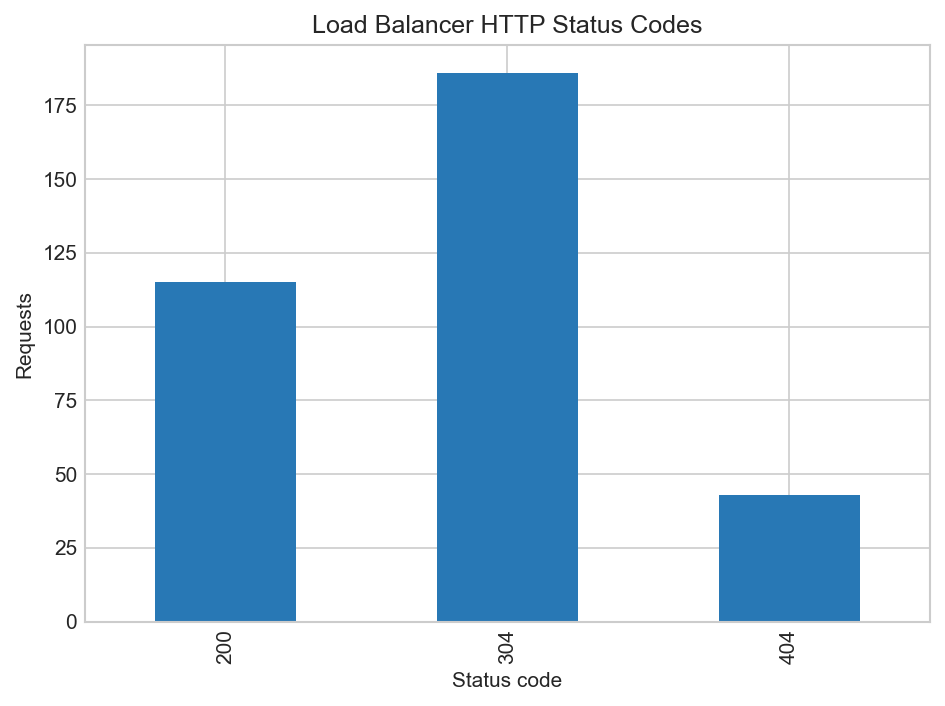

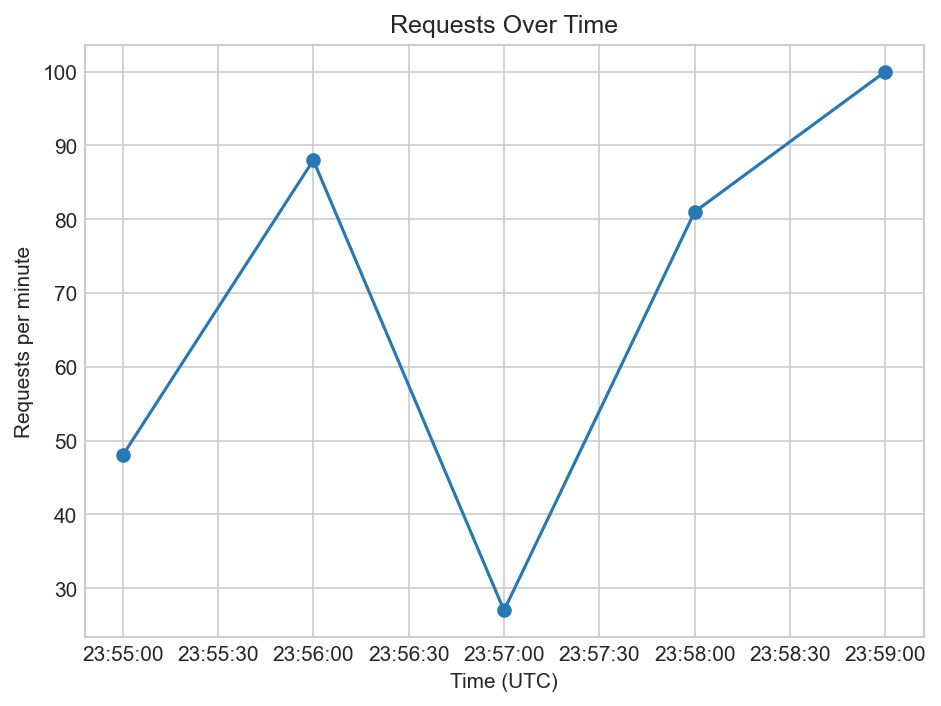

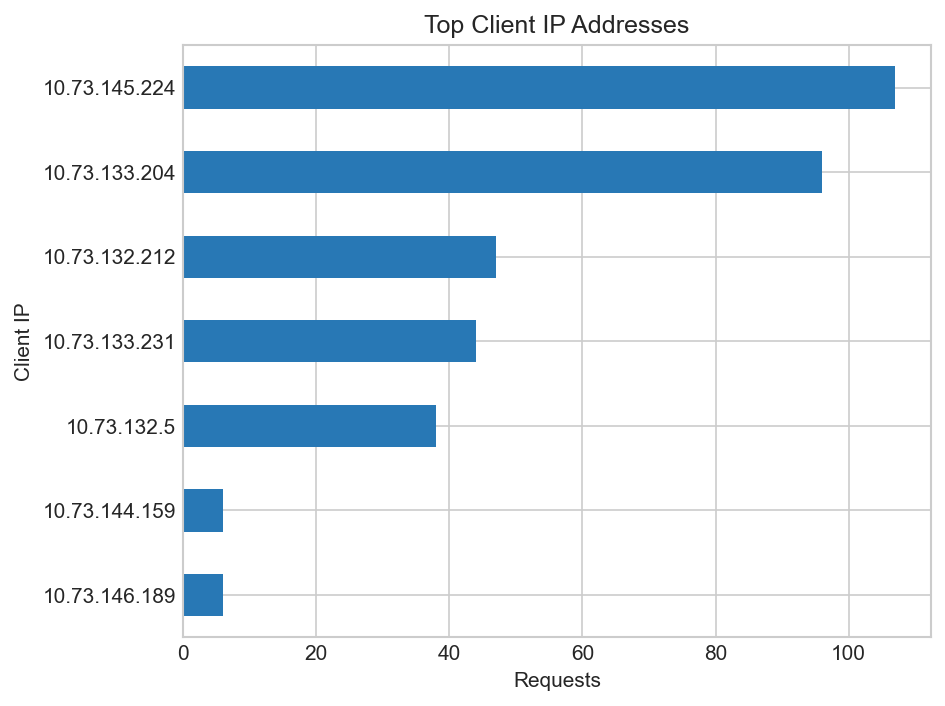

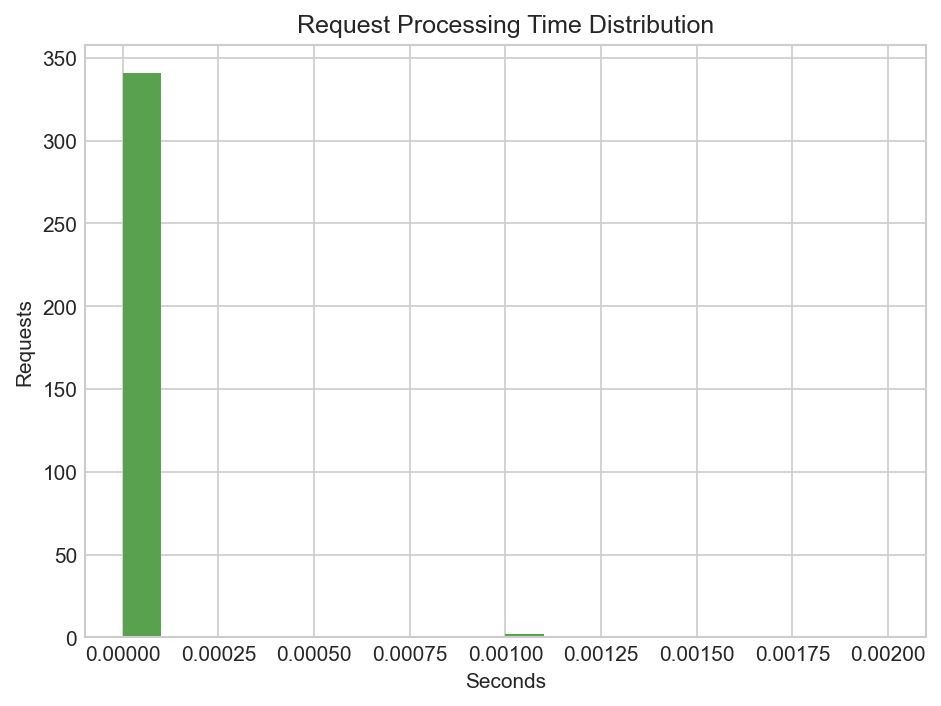

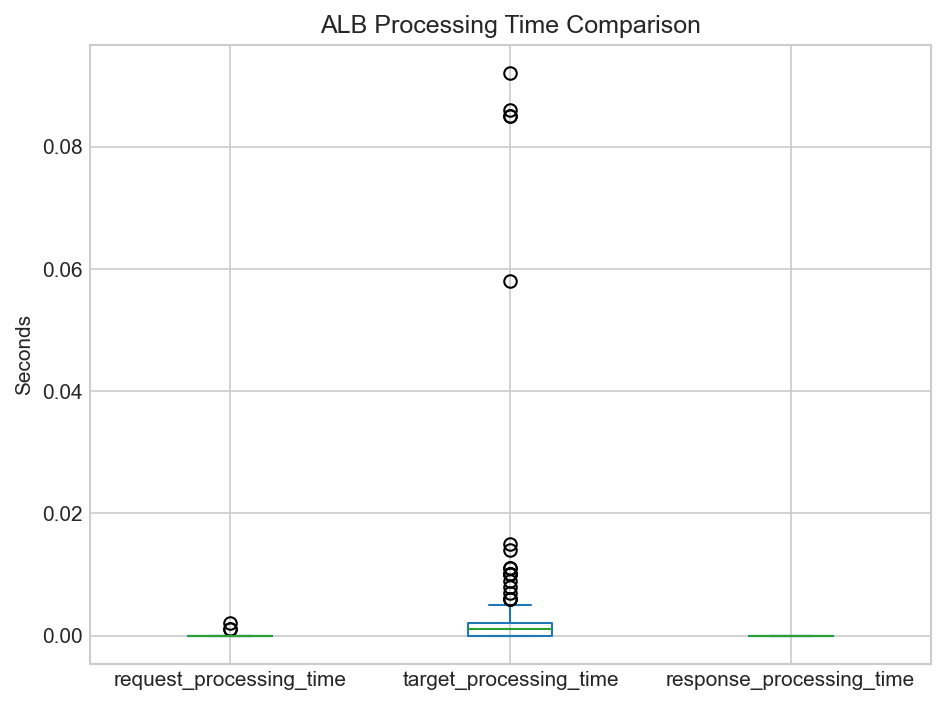

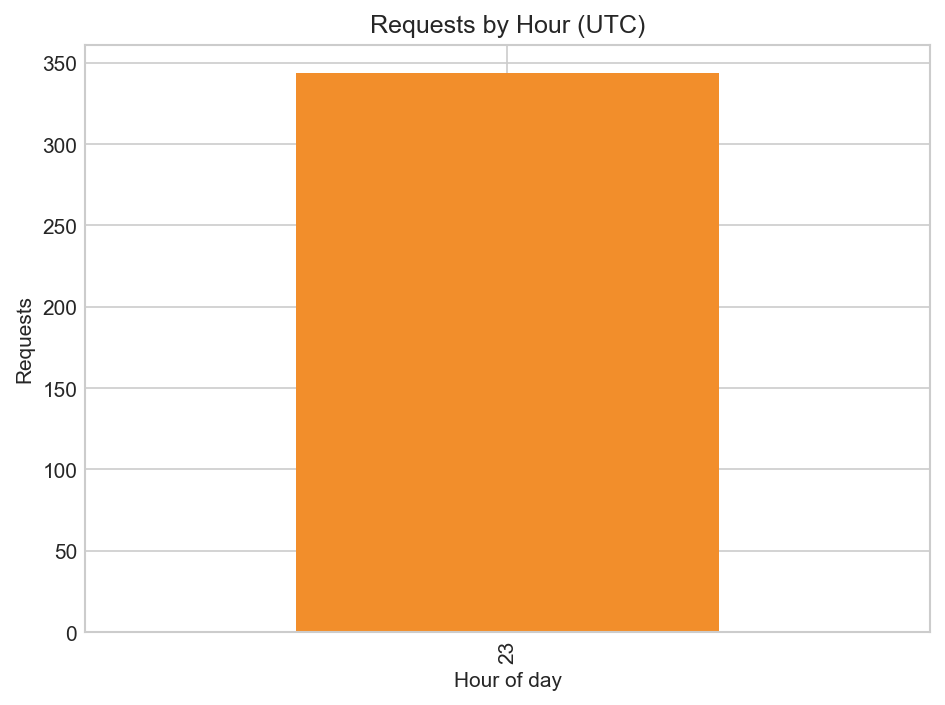

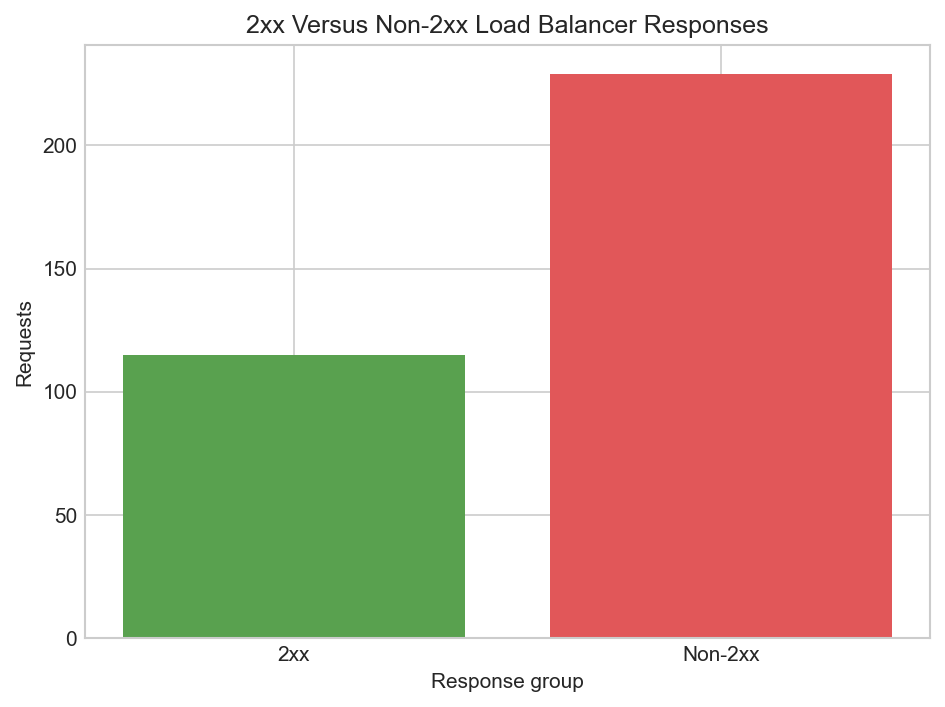

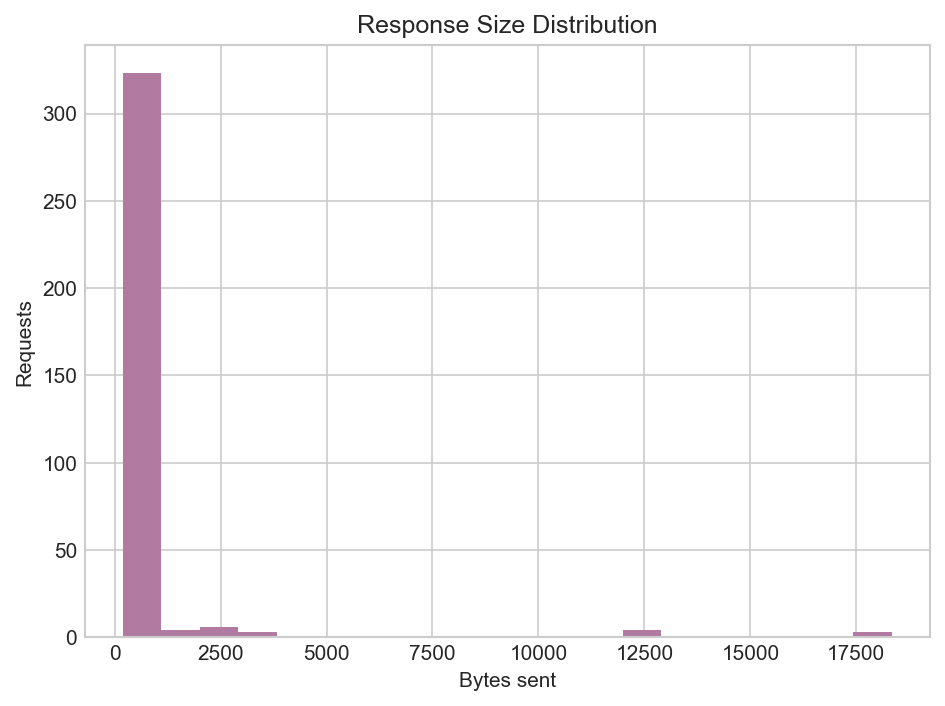

Saved 8 charts to C:\projects\Python Project\reports\charts


In [16]:
plt.style.use("seaborn-v0_8-whitegrid")
chart_files = []

def save_chart(filename):
    plt.tight_layout()
    plt.savefig(CHART_DIR / filename, dpi=150, bbox_inches="tight")
    plt.close()
    display(Image(filename=str(CHART_DIR / filename)))
    chart_files.append(filename)

# 1. HTTP status distribution
df["elb_status_code"].dropna().astype(int).value_counts().sort_index().plot(kind="bar", color="#2878B5")
plt.title("Load Balancer HTTP Status Codes")
plt.xlabel("Status code")
plt.ylabel("Requests")
save_chart("status_code_distribution.png")

# 2. Requests over time
plt.plot(requests_by_minute["minute_utc"], requests_by_minute["requests"], marker="o", color="#2878B5")
plt.title("Requests Over Time")
plt.xlabel("Time (UTC)")
plt.ylabel("Requests per minute")
if len(requests_by_minute) == 1:
    only_minute = requests_by_minute["minute_utc"].iloc[0]
    plt.xlim(only_minute - pd.Timedelta(seconds=30), only_minute + pd.Timedelta(seconds=30))
save_chart("requests_over_time.png")

# 3. Top client addresses
requests_by_ip.head(10).sort_values("requests").plot(
    kind="barh", x="client_ip", y="requests", legend=False, color="#2878B5"
)
plt.title("Top Client IP Addresses")
plt.xlabel("Requests")
plt.ylabel("Client IP")
save_chart("top_client_ips.png")

# 4. Request processing time histogram
df["request_processing_time"].dropna().plot(kind="hist", bins=20, color="#59A14F")
plt.title("Request Processing Time Distribution")
plt.xlabel("Seconds")
plt.ylabel("Requests")
save_chart("request_processing_time_histogram.png")

# 5. Processing time box plot
df[timing_columns].apply(pd.to_numeric, errors="coerce").plot(kind="box")
plt.title("ALB Processing Time Comparison")
plt.ylabel("Seconds")
save_chart("processing_time_comparison.png")

# 6. Requests by hour
requests_by_hour.plot(kind="bar", x="hour_utc", y="requests", legend=False, color="#F28E2B")
plt.title("Requests by Hour (UTC)")
plt.xlabel("Hour of day")
plt.ylabel("Requests")
save_chart("requests_by_hour.png")

# 7. Successful 2xx versus all other returned status codes
success_count = int(status_values.between(200, 299).sum())
other_count = int((~status_values.between(200, 299)).sum())
plt.bar(["2xx", "Non-2xx"], [success_count, other_count], color=["#59A14F", "#E15759"])
plt.title("2xx Versus Non-2xx Load Balancer Responses")
plt.xlabel("Response group")
plt.ylabel("Requests")
save_chart("successful_vs_other_responses.png")

# 8. Response size histogram (bytes sent by the load balancer)
df["sent_bytes"].dropna().plot(kind="hist", bins=20, color="#B07AA1")
plt.title("Response Size Distribution")
plt.xlabel("Bytes sent")
plt.ylabel("Requests")
save_chart("response_size_histogram.png")

print(f"Saved {len(chart_files)} charts to {CHART_DIR}")

## 11. Validation checks (Stage 9)

These lightweight assertions check that the core parser and analysis behave as expected. The test string is synthetic and contains no values from the supplied log.

In [17]:
sample_line = (
    'http 2021-10-05T23:55:13.192364Z app/test/abc '
    '10.0.0.1:40824 10.0.0.2:80 0.000 0.001 0.000 200 200 337 266 '
    '"GET https://example.test/path?q=one HTTP/1.1" "Example Agent" - - '
    'arn:aws:elasticloadbalancing:region:000000000000:targetgroup/name/id '
    '"Root=trace" "example.test" - 1 2021-10-05T23:55:13.190000Z '
    'forward - - "10.0.0.2:80" "200" - -'
)
sample = parse_alb_line(sample_line)
assert sample["client_ip"] == "10.0.0.1"
assert sample["request_path"] == "/path"
assert sample["user_agent"] == "Example Agent"
assert sample["elb_status_code"] == 200
assert frequency(["x", "x", "y"]) == {"x": 2, "y": 1}
assert frequency(["200", "404"]) == {"200": 1, "404": 1}
assert numpy_stats(pd.Series([], dtype=float))["mean"] is None

try:
    parse_alb_line("not a complete ALB row")
except LogParseError:
    malformed_record_check = "passed"
else:
    raise AssertionError("A short malformed record should be rejected")

print("Parser, quoting, missing-value, frequency, and empty-statistic checks passed.")
print(f"Malformed-record check: {malformed_record_check}")

Parser, quoting, missing-value, frequency, and empty-statistic checks passed.
Malformed-record check: passed


## 12. Run summary and checkpoint (Stage 8)

`main.py` is replaced here by the notebook's top-to-bottom cell flow. The following summary records actual counts from this input. Review the CSVs and charts in the project folder. Stage 10 can add sanitized portfolio screenshots and GitHub publishing instructions.

In [18]:
run_summary = {
    "input_file": str(LOG_FILE),
    "parsed_records": len(records),
    "invalid_records": len(invalid_records),
    "traffic": traffic_summary,
    "status_analysis": status_summary,
    "anomaly_review_flags": len(anomalies),
    "charts_created": chart_files,
}
summary_path = REPORT_DIR / "run_summary.json"
summary_path.write_text(json.dumps(run_summary, indent=2, default=str), encoding="utf-8")
print(json.dumps(run_summary, indent=2, default=str))
print(f"\nSaved summary: {summary_path}")

{
  "input_file": "C:\\projects\\Python Project\\mylog.log",
  "parsed_records": 344,
  "invalid_records": 0,
  "traffic": {
    "total_requests": 344,
    "unique_client_ips": 7,
    "time_start_utc": "2021-10-05T23:55:13.192364+00:00",
    "time_end_utc": "2021-10-05T23:59:57.604600+00:00"
  },
  "status_analysis": {
    "load_balancer_counts": {
      "304": 186,
      "200": 115,
      "404": 43
    },
    "target_counts": {
      "304": 186,
      "200": 115,
      "404": 43
    },
    "successful_2xx": 115,
    "redirect_responses": 0,
    "not_modified_304": 186,
    "client_errors_4xx": 43,
    "server_errors_5xx": 0,
    "success_percent": 33.43,
    "error_percent": 12.5
  },
  "anomaly_review_flags": 17,
  "charts_created": [
    "status_code_distribution.png",
    "requests_over_time.png",
    "top_client_ips.png",
    "request_processing_time_histogram.png",
    "processing_time_comparison.png",
    "requests_by_hour.png",
    "successful_vs_other_responses.png",
    "resp